<a href="https://colab.research.google.com/github/Ursineblock/Projeto-deep-learning/blob/main/projeto_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub, os
path = kagglehub.dataset_download("mostafaabla/garbage-classification")

# Acha a pasta que tem várias subpastas de classe com imagens
data_dir = None
for root, dirs, files in os.walk(path):
    if len(dirs) >= 10 and not files:
        data_dir = root
        break
print(data_dir, sorted(os.listdir(data_dir)))

Using Colab cache for faster access to the 'garbage-classification' dataset.
/kaggle/input/garbage-classification/garbage_classification ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


In [ ]:
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

# Definir transformações básicas para as imagens
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Carregar o dataset a partir do data_dir encontrado anteriormente
full_train = datasets.ImageFolder(root=data_dir, transform=data_transforms)
full_eval = datasets.ImageFolder(root=data_dir, transform=data_transforms)

targets = full_train.targets
idx_all = list(range(len(targets)))
idx_tr, idx_tmp = train_test_split(idx_all, test_size=0.3, stratify=targets, random_state=42)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.5,
                                  stratify=[targets[i] for i in idx_tmp], random_state=42)

train_dl = DataLoader(Subset(full_train, idx_tr), batch_size=32, shuffle=True)
val_dl   = DataLoader(Subset(full_eval, idx_va), batch_size=32)
test_dl  = DataLoader(Subset(full_eval, idx_te), batch_size=32)

print(f"Dataset carregado com sucesso!")
print(f"Treino: {len(idx_tr)} | Validação: {len(idx_va)} | Teste: {len(idx_te)}")

Dataset carregado com sucesso!
Treino: 10860 | Validação: 2327 | Teste: 2328


In [ ]:
import torch, torch.nn as nn
from torchvision import models

# Define o número de classes com base nas classes identificadas no dataset carregado
num_classes = len(full_train.classes)

model = models.resnet18(weights="IMAGENET1K_V1")
model.fc = nn.Linear(model.fc.in_features, num_classes)

print(f"Modelo carregado com sucesso para {num_classes} classes!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


Modelo carregado com sucesso para 12 classes!


In [ ]:
import torch
import torch.nn as nn

# Verificar se GPU está disponível
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Definir função de perda e otimizador
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def run_epoch(dataloader, is_training):
    if is_training:
        model.train()
    else:
        model.eval()

    running_loss = 0.0
    running_corrects = 0
    total_samples = 0

    for inputs, labels in dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Zera os gradientes no modo de treino
        if is_training:
            optimizer.zero_grad()

        # Habilita o cálculo de gradientes apenas se estiver treinando
        with torch.set_grad_enabled(is_training):
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)

            if is_training:
                loss.backward()
                optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data).item()
        total_samples += inputs.size(0)

    epoch_loss = running_loss / total_samples
    epoch_acc = running_corrects / total_samples
    return epoch_loss, epoch_acc

history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}

for ep in range(30):
    tl, ta = run_epoch(train_dl, True)
    vl, va = run_epoch(val_dl, False)
    history["train_loss"].append(tl); history["train_acc"].append(ta)
    history["val_loss"].append(vl);   history["val_acc"].append(va)
    print(f"Época {ep+1}: treino acc {ta:.3f} | val acc {va:.3f} | val loss {vl:.3f}")

In [ ]:
torch.save(model.state_dict(), "resnet18_lixo.pth")

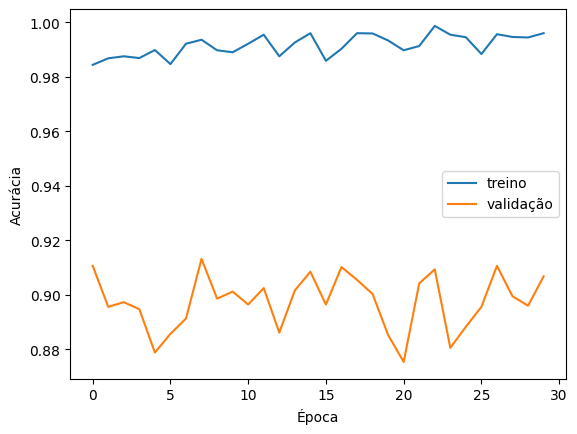

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history["train_acc"], label="treino")
plt.plot(history["val_acc"], label="validação")
plt.xlabel("Época"); plt.ylabel("Acurácia"); plt.legend(); plt.show()